# 04 — Global & Customer-Level SHAP Model Explainability

Inspects global SHAP feature importance, dependence plots, and an individual customer risk breakdown using the exact serialized production pipeline.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display
from src.config import SHAP_SUMMARY_PATH, FIGURES_DIR
from src.predict import ChurnPredictor

with open(SHAP_SUMMARY_PATH, 'r', encoding='utf-8') as f:
    shap_summary = json.load(f)
print('Explainer:', shap_summary['explainer_type'], '| Evaluated Rows:', shap_summary['evaluated_rows'])
pd.DataFrame(shap_summary['top_global_features'])

Explainer: TreeExplainer | Evaluated Rows: 1409


/home/talha/Projects/churn/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,display_name,mean_abs_shap,mean_signed_shap
0,Contract_Month-to-month,Contract: Month-to-month,0.5297,-0.1141
1,tenure,Tenure (months),0.4239,-0.1132
2,InternetService_Fiber optic,InternetService: Fiber optic,0.2541,-0.0507
3,OnlineSecurity_No,OnlineSecurity: No,0.2505,-0.0515
4,Contract_Two year,Contract: Two year,0.1938,-0.0500
5,TechSupport_No,TechSupport: No,0.1648,-0.0415
6,PaymentMethod_Electronic check,PaymentMethod: Electronic check,0.1614,-0.0320
7,avg_monthly_spend,Avg Monthly Spend ($),0.1352,-0.0365
8,MonthlyCharges,Monthly Charges ($),0.1151,-0.0287
9,TotalCharges,Total Charges ($),0.0892,-0.0146


14_shap_summary_beeswarm.png


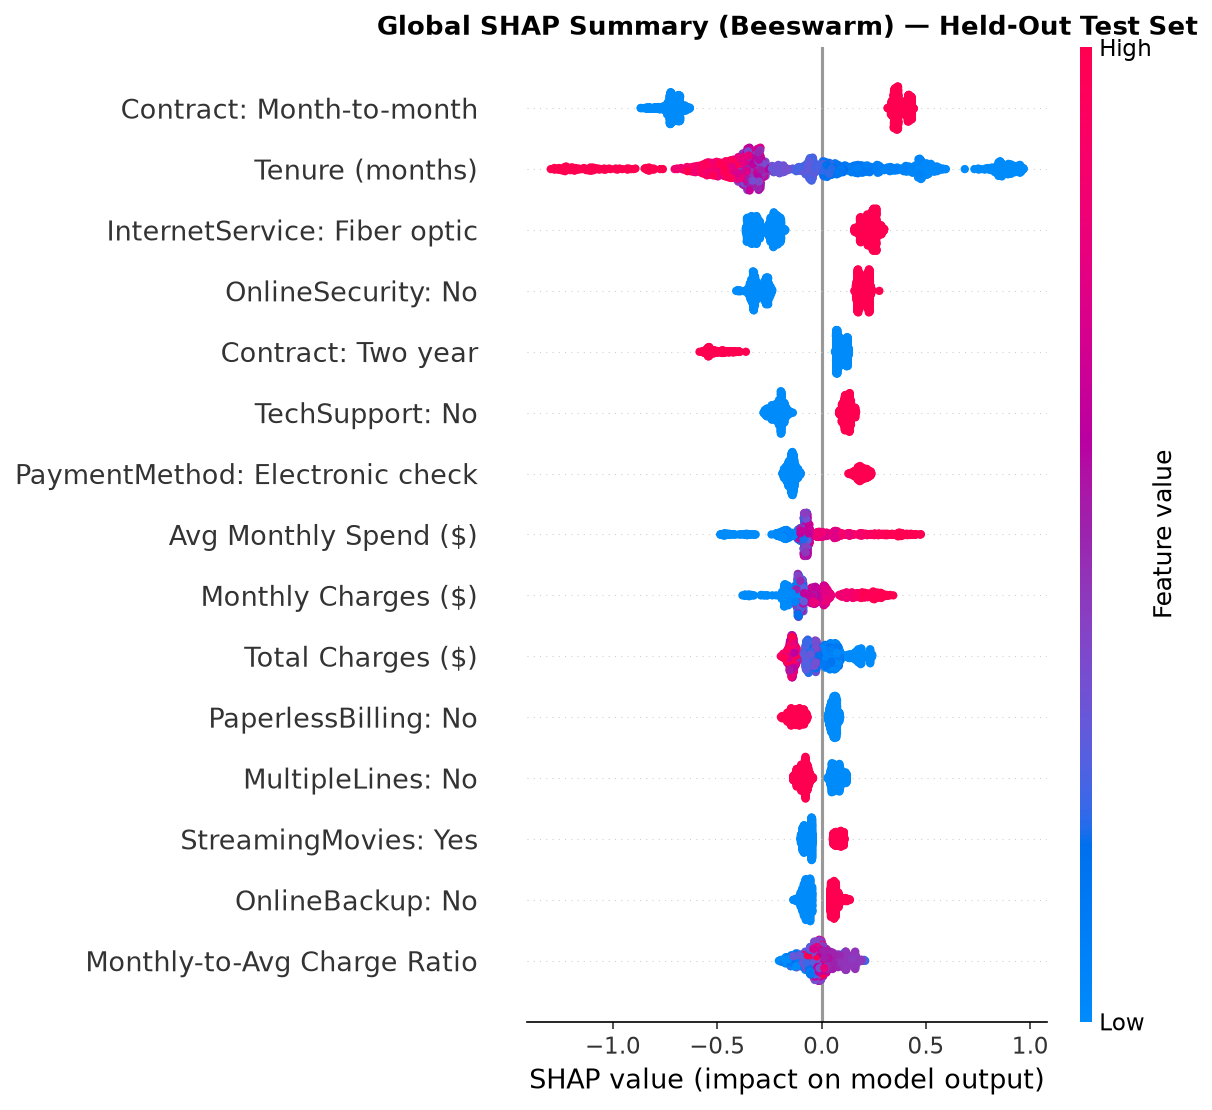

15_shap_feature_importance_bar.png


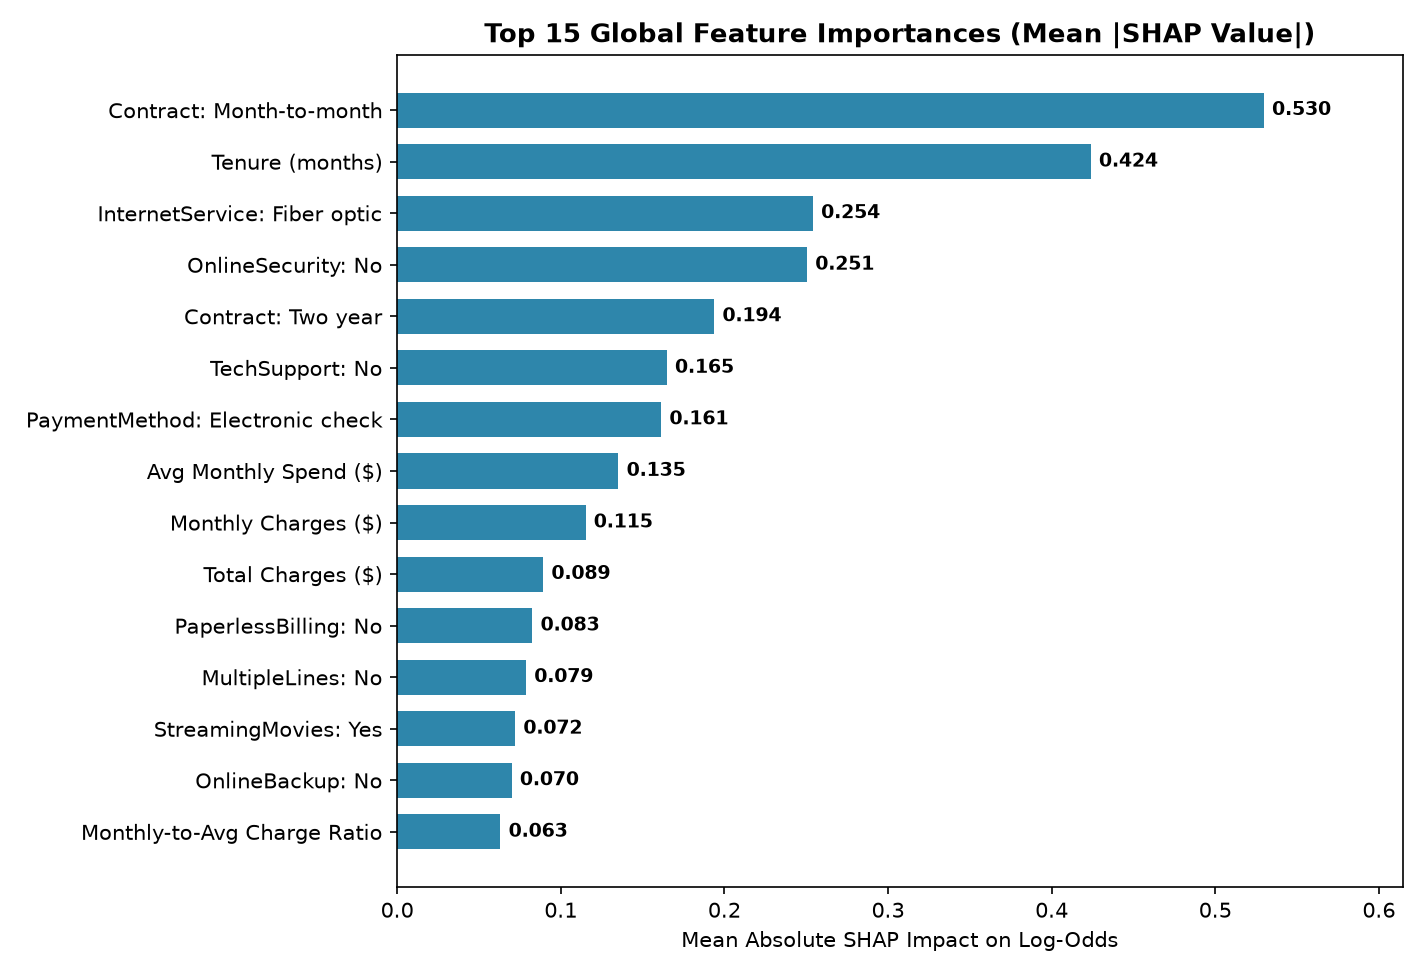

16_shap_dependence_top_features.png


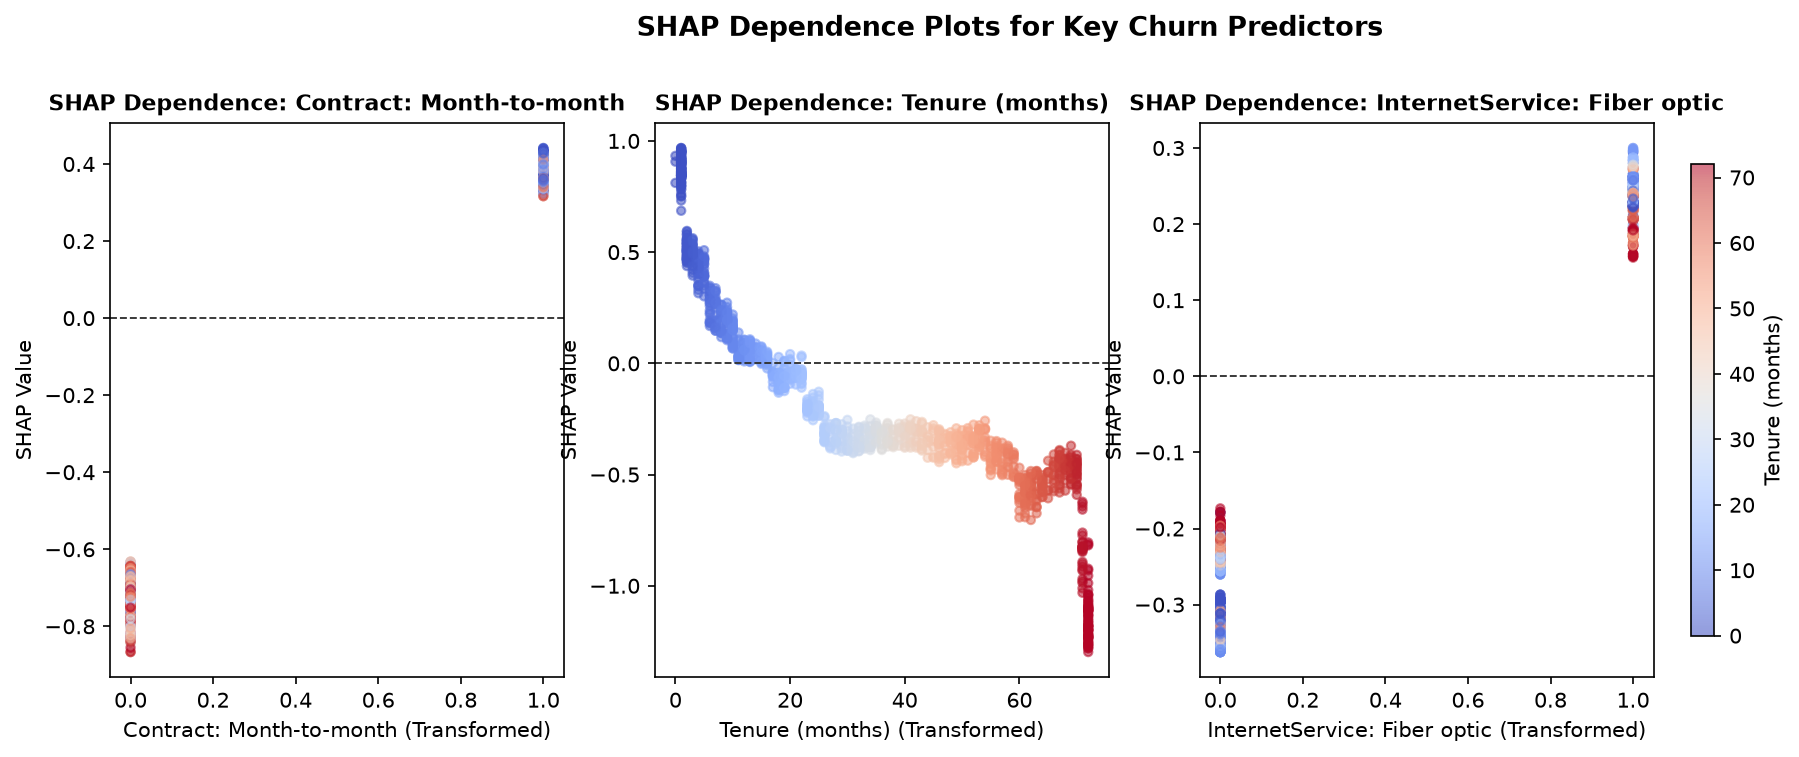

17_shap_local_high_risk_example.png


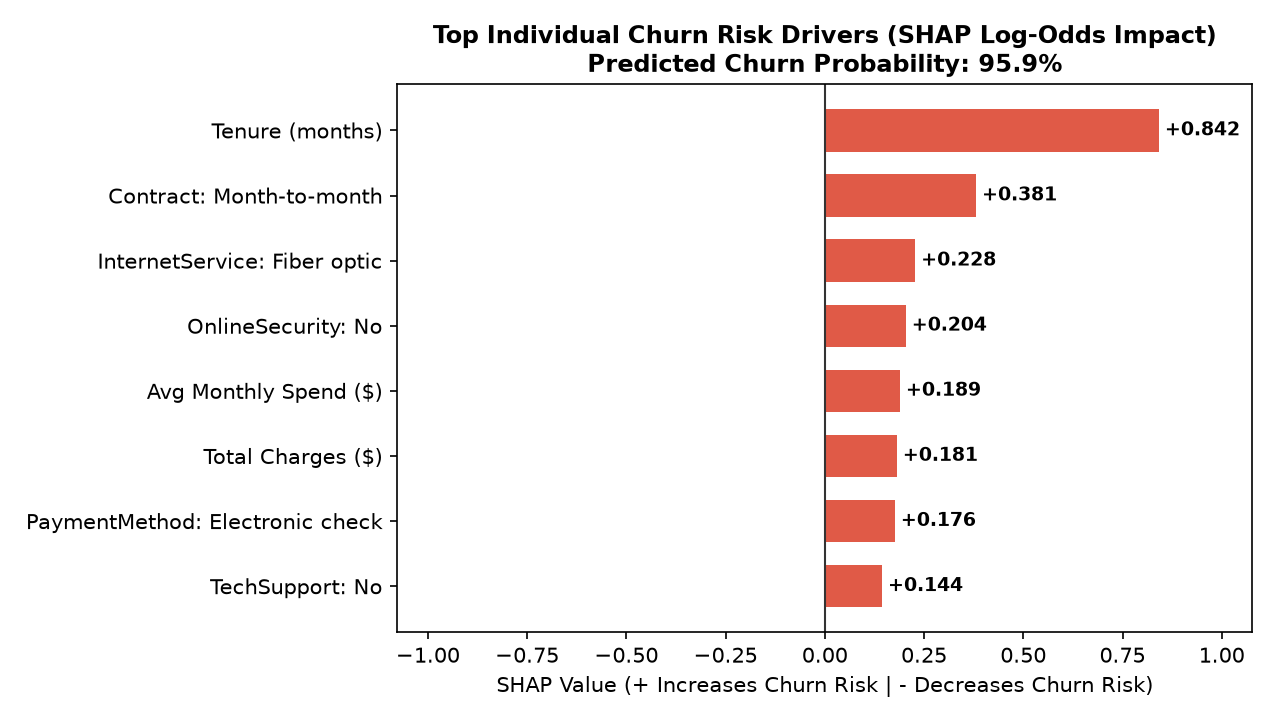

In [2]:
for fname in ['14_shap_summary_beeswarm.png', '15_shap_feature_importance_bar.png', '16_shap_dependence_top_features.png', '17_shap_local_high_risk_example.png']:
    p = FIGURES_DIR / fname
    if p.exists():
        print(fname)
        display(Image(filename=str(p), width=780))

In [3]:
# Run live individual prediction + SHAP explanation through ChurnPredictor
predictor = ChurnPredictor()
sample = shap_summary['sample_high_risk_customer']['profile']
res = predictor.predict_one(sample, include_explanation=True)
print(f"Predicted Churn Probability: {res['churn_probability']:.2%} ({res['risk_category']} Risk)")
print('Top Risk-Increasing Factors:', res['explanation']['top_risk_increasing_factors'])
print('Retention Considerations:')
for r in res['explanation']['retention_considerations']:
    print(' -', r)

Predicted Churn Probability: 95.94% (High Risk)
Top Risk-Increasing Factors: ['Tenure (months)', 'Contract: Month-to-month', 'InternetService: Fiber optic']
Retention Considerations:
 - Month-to-month contract is a primary risk driver: consider evaluating a targeted 1-year or 2-year contract migration incentive (e.g., loyalty discount or waived upgrade fee).
 - Early-tenure lifecycle risk: prioritize proactive onboarding check-ins and first-year service satisfaction outreach before the initial renewal friction window.
 - Fiber optic service shows elevated churn association: audit line quality/speed tickets and review pricing competitiveness against comparable plans.
 - Missing Tech Support / Online Security add-ons increased predicted risk: test bundling a complimentary trial of technical support or security protection.
 - Electronic check payment is associated with higher churn: consider offering a small billing credit for enrolling in automatic bank transfer or credit-card autopay.
